# Gradient Descent

In [8]:
from sklearn.datasets import make_regression
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 

from sklearn.linear_model import LinearRegression

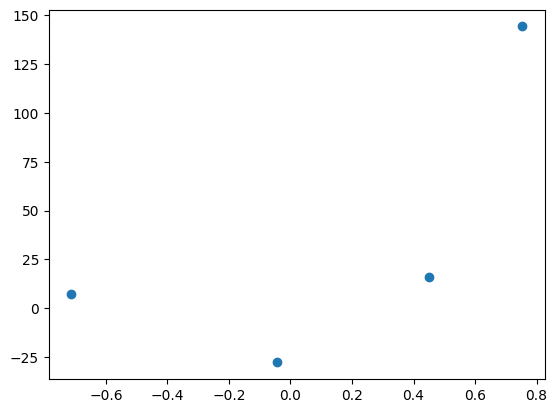

In [9]:
X, y = make_regression(n_samples=4, n_features=1,n_informative=1, n_targets=1, noise=80, random_state=13)
plt.scatter(X, y)

In [11]:
# Let's apply OLS
from sklearn.linear_model import LinearRegression

reg = LinearRegression(
    fit_intercept=True,
    copy_X=True,
    n_jobs=None
)

reg.fit(X, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[78.35]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,26.16
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,1
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[1.11]


In [12]:
reg.coef_

array([78.35063668])

In [14]:
reg.intercept_

np.float64(26.15963284313262)

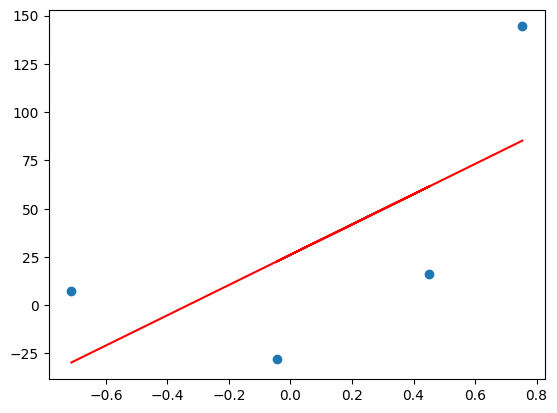

In [16]:
plt.scatter(X, y)
plt.plot(X, reg.predict(X), color='red')

In [17]:
# Let's apply gradient descent assuming slope is constant m = 78.35
# And let's assume the starting value for intercept b = 0 

y_pred = ((78.35 * X + 0).reshape(4))

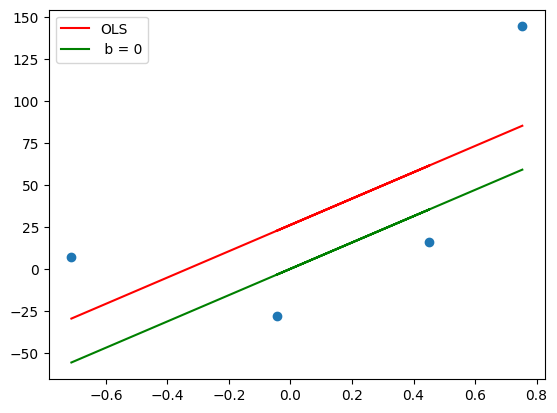

In [18]:
plt.scatter(X,y)
plt.plot(X, reg.predict(X), color='red', label='OLS')
plt.plot(X, y_pred, color='green', label= ' b = 0')
plt.legend()
plt.show()

In [20]:
m = 78.35
b = 0

loss_slope = -2 * np.sum( y - m*X.ravel() - b)
loss_slope

np.float64(-209.27763408209216)

In [21]:
# Let's take learning rate = 0.01 and update the value of b

lr = 0.1
step_size = loss_slope * lr
step_size

np.float64(-20.927763408209216)

In [22]:
# Calculating the new intercept value after the first iteration

b = b - step_size
b

np.float64(20.927763408209216)

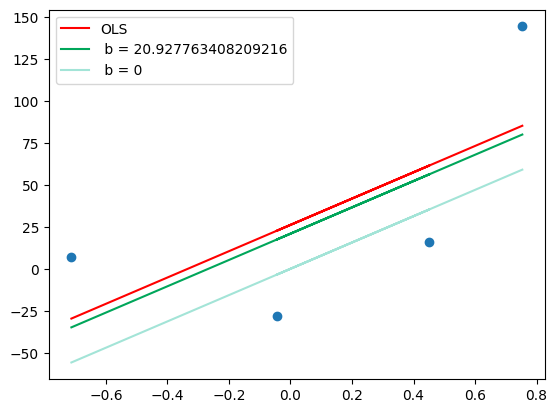

In [25]:
y_pred1 = ((78.35 * X + b).reshape(4))

plt.scatter(X,y)
plt.plot(X, reg.predict(X), color='RED', label='OLS')
plt.plot(X, y_pred1, color='#00a65a', label= ' b = {}'.format(b))
plt.plot(X, y_pred, color='#A3E4D7', label= ' b = 0')
plt.legend()
plt.show()

In [26]:
# Iteration 2

loss_slope = -2 * np.sum( y - m*X.ravel() - b)
loss_slope

np.float64(-41.85552681641843)

In [27]:
step_size = loss_slope * lr
step_size

np.float64(-4.185552681641844)

In [28]:
b = b - step_size
b

np.float64(25.11331608985106)

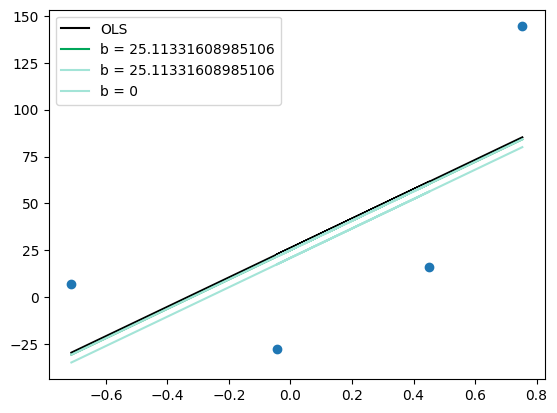

In [31]:
y_pred2 = ((78.35 * X + b).reshape(4))

plt.scatter(X, y)
plt.plot(X, reg.predict(X), color='black', label='OLS')
plt.plot(X, y_pred2, color='#00a65a', label='b = {}'.format(b))
plt.plot(X, y_pred1, color='#A3E4D7', label='b = {}'.format(b))
plt.plot(X, y_pred, color='#A3E4D7', label='b = 0')

plt.legend()
plt.show()

In [32]:
# Iteration 3

loss_slope = -2 * np.sum( y - m*X.ravel() - b)
loss_slope

np.float64(-8.371105363283675)

In [33]:
step_size = loss_slope * lr
step_size

np.float64(-0.8371105363283675)

In [34]:
b = b - step_size
b

np.float64(25.95042662617943)

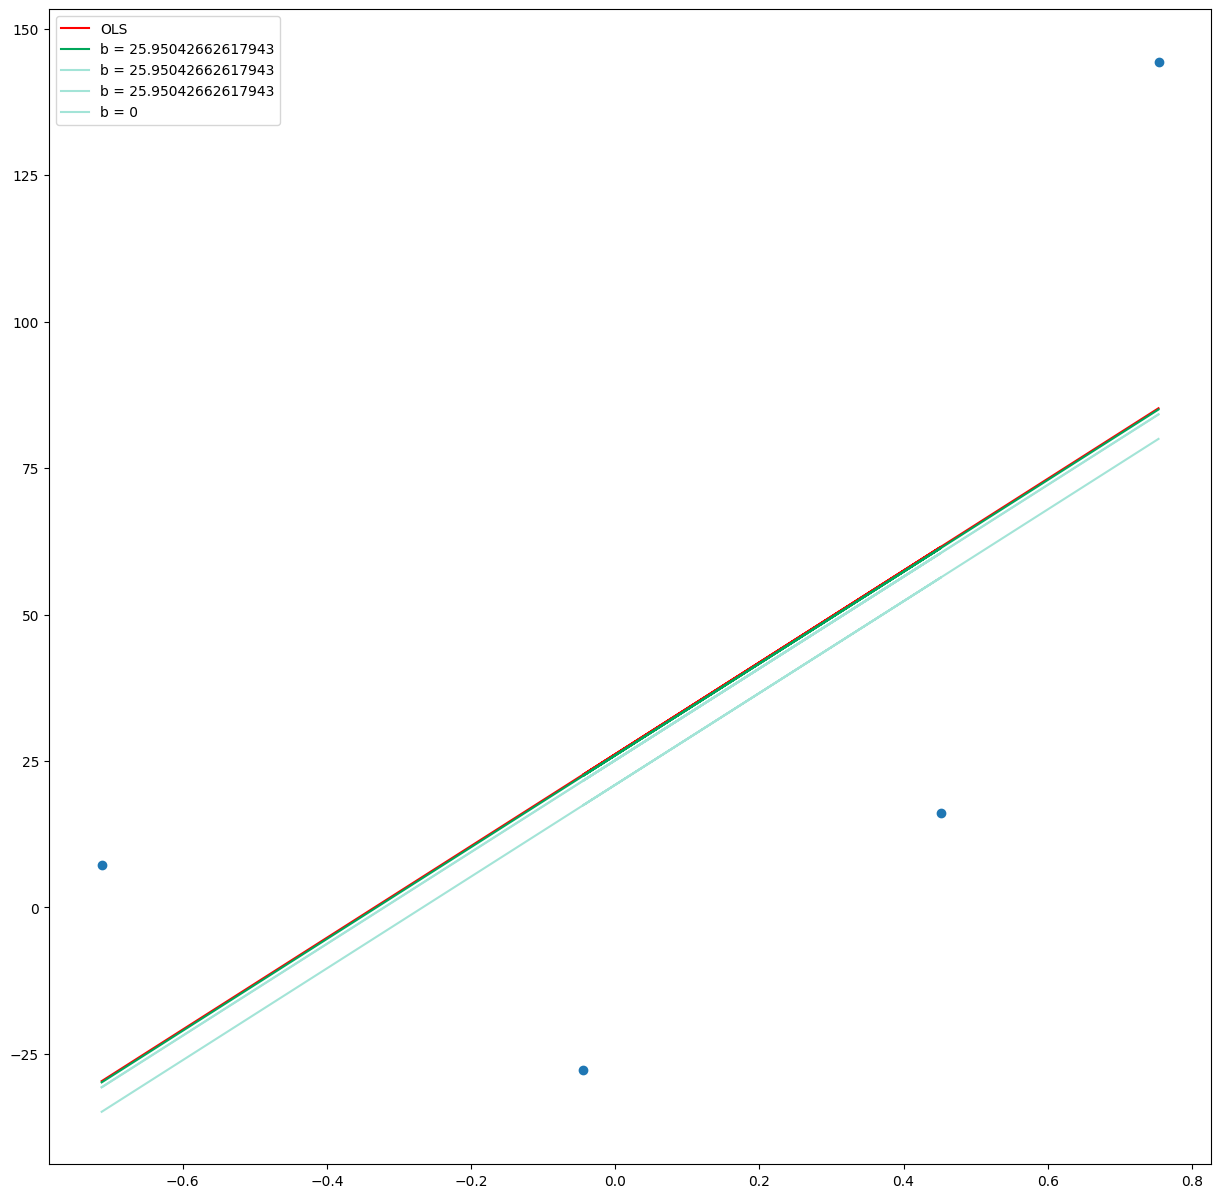

In [36]:
y_pred3 = ((78.35 * X) + b).reshape(4)

plt.figure(figsize=(15,15))

plt.scatter(X, y)
plt.plot(X, reg.predict(X), color='red', label='OLS')
plt.plot(X, y_pred3, color='#00a65a', label='b = {}'.format(b))
plt.plot(X, y_pred2, color='#A3E4D7', label='b = {}'.format(b))
plt.plot(X, y_pred1, color='#A3E4D7', label='b = {}'.format(b))
plt.plot(X, y_pred, color='#A3E4D7', label='b = 0')

plt.legend()
plt.show()

# Creating our own class and methods

In [37]:
from sklearn.datasets import make_regression
import matplotlib.pyplot as plt
import numpy as np

In [38]:
X, y = make_regression(n_samples=100, n_features=1, n_informative=1, n_targets=1, noise=20)

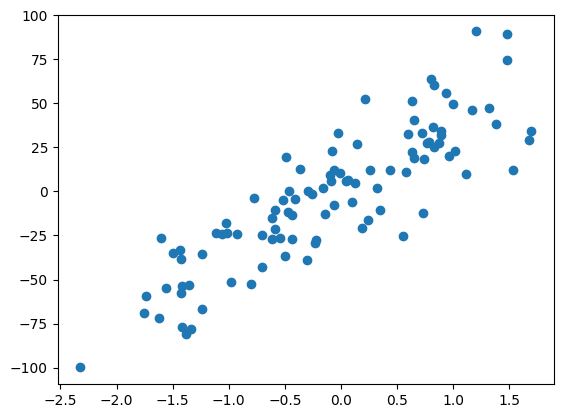

In [39]:
plt.scatter(X,y)

In [41]:
from sklearn.linear_model import LinearRegression
lr = LinearRegression()
lr.fit(X,y)
print('slope :',lr.coef_)
print('intercept :',lr.intercept_)

slope : [35.77038452]
intercept : 0.8783606299670295


In [42]:
m = 29.19


In [54]:
class GDRegressor:
    def __init__(self, learning_rate, epochs):
        self.m = 29.19
        self.b = -120
        self.lr = learning_rate
        self.epochs = epochs

    def fit(self,X, y):
        # Calculate the b using GD
        for i in range(self.epochs):
            loss_slope = -2 * np.sum( y - self.m*X.ravel() - self.b)
            self.b = self.b - (self.lr * loss_slope)
            print(loss_slope, self.b)
        print(self.b)

In [55]:
gd = GDRegressor(0.001,100)

In [56]:
gd.fit(X,y)

-24051.165092514686 -95.94883490748532
-19240.932074011747 -76.70790283347357
-15392.7456592094 -61.315157174264165
-12314.196527367518 -49.000960646896644
-9851.357221894013 -39.14960342500263
-7881.085777515213 -31.268517647487418
-6304.868622012169 -24.96364902547525
-5043.894897609735 -19.919754127865513
-4035.115918087788 -15.884638209777725
-3228.0927344702304 -12.656545475307494
-2582.4741875761842 -10.07407128773131
-2065.979350060947 -8.008091937670363
-1652.783480048758 -6.355308457621605
-1322.2267840390061 -5.033081673582599
-1057.781427231205 -3.9753002463513933
-846.2251417849639 -3.1290751045664296
-676.9801134279711 -2.452094991138458
-541.5840907423769 -1.9105109003960812
-433.26727259390157 -1.4772436278021797
-346.6138180751213 -1.1306298097270584
-277.291054460097 -0.8533387552669613
-221.8328435680774 -0.6315059116988839
-177.466274854462 -0.45403963684442195
-141.9730198835696 -0.31206661696085236
-113.57841590685572 -0.19848820105399662
-90.86273272548469 -0.1076

# modify code to calculate value of m and b

In [84]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_regression
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score

In [85]:
X,y = make_regression(n_samples=100, n_features=1, n_informative=1, n_targets=1, noise=20, random_state=13)

# n_samples=100 :- number of observations (rows) in the dataset.
# n_features=1 :- number of independent variables (input features).
# n_informative=1 :- how many features actually influence the target
# n_targets=1 :- the number of target variables.
# noise=20 :- adds random noise to the target values.
# random_state=13 :- It ensures the same dataset is generated every time you run the code

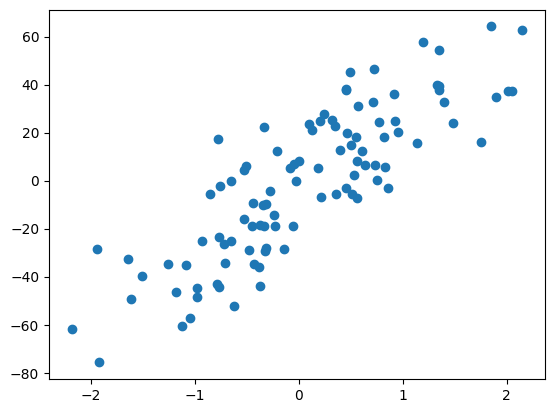

In [86]:
plt.scatter(X,y)

In [87]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=2)

In [88]:
lr = LinearRegression()

In [89]:
lr.fit(X_train,y_train)
print(lr.coef_)
print(lr.intercept_)

[28.12597332]
-2.2710144261783825


In [90]:
y_pred = lr.predict(X_test)
from sklearn.metrics import r2_score
r2_score(y_test, y_pred)

0.6345158782661012

In [91]:
np.mean (cross_val_score(lr,X,y, scoring='r2', cv=10))

np.float64(0.6375011587464419)

In [92]:
class GDRegressor :
    def __init__(self, learning_rate, epochs):
        self.m = 100
        self.b = -120
        self.lr = learning_rate
        self.epochs = epochs
    
    def fit (self, X, y):
        # calculate the b using GD
        for i in range(self.epochs):
            loss_slope_b = -2 * np.sum(y - self.m*X.ravel() - self.b) 
            loss_slope_m = -2 * np.sum((y - self.m*X.ravel() - self.b)* X.ravel()) 
            
            self.b = self.b = (self.lr * loss_slope_b)
            self.m = self.m = (self.lr * loss_slope_m)
        print(self.m, self.b)

    def predict(self,X):
        return self.m *X + self.b

In [93]:
gd = GDRegressor(0.001, 50)

In [94]:
gd.fit(X_train, y_train)

-5.009351024783815 0.11291760395799173


In [95]:
y_pred = gd.predict(X_test)
from sklearn.metrics import r2_score
r2_score(y_test, y_pred)

-0.27258270143289876